In [2]:
import numpy as np
import matplotlib.pyplot as plt



In [3]:

class LinearRegressionScratch:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for i in range(self.n_iterations):
            y_pred = np.dot(X, self.weights) + self.bias

            error = y_pred - y
            dw = (2 / n_samples) * np.dot(X.T, error)
            db = (2 / n_samples) * np.sum(error)

            self.weights -= self.lr * dw
            self.bias    -= self.lr * db

            loss = np.mean(error ** 2)
            self.loss_history.append(loss)

            if i % 100 == 0:
                print(f"Iter {i:4d} | MSE = {loss:.6f}")

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

In [ ]:
np.random.seed(42)
X = 2 * np.random.rand(100, 1)
y = 4 + 3 * X.flatten() + np.random.randn(100)   # y = 4 + 3x + noise

model = LinearRegressionScratch(learning_rate=0.1, n_iterations=1000)
model.fit(X, y)

print(f"\nTrue     → w = 3.0, b = 4.0")
print(f"Predicted→ w = {model.weights[0]:.3f}, b = {model.bias:.3f}")

y_pred = model.predict(X)

Iter    0 | MSE = 50.008304
Iter  100 | MSE = 0.806883
Iter  200 | MSE = 0.806585
Iter  300 | MSE = 0.806585
Iter  400 | MSE = 0.806585
Iter  500 | MSE = 0.806585
Iter  600 | MSE = 0.806585
Iter  700 | MSE = 0.806585
Iter  800 | MSE = 0.806585
Iter  900 | MSE = 0.806585

True     → w = 3.0, b = 4.0
Predicted→ w = 2.770, b = 4.215


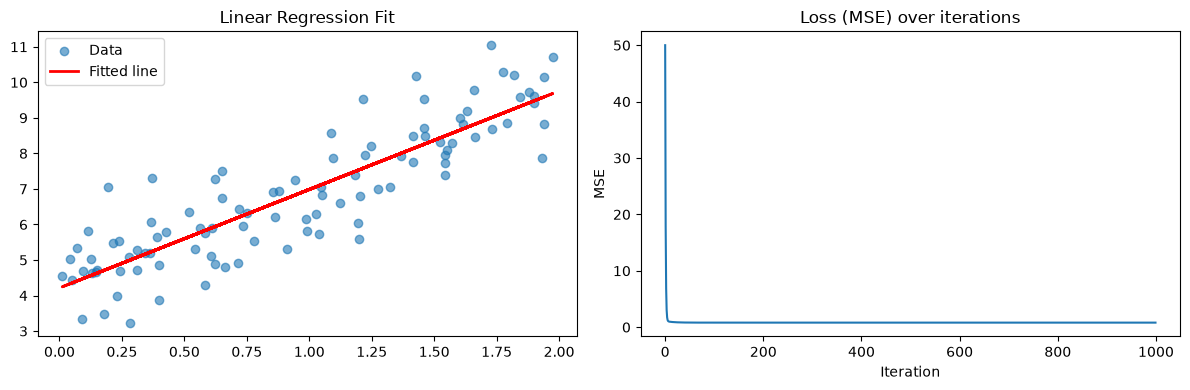

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X, y, alpha=0.6, label="Data")
axes[0].plot(X, y_pred, color="red", linewidth=2, label="Fitted line")
axes[0].set_title("Linear Regression Fit")
axes[0].legend()

axes[1].plot(model.loss_history)
axes[1].set_title("Loss (MSE) over iterations")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("MSE")

plt.tight_layout()
plt.show()